1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier


2. Load the dataset and separating target and features

In [3]:
# Load dataset
df = pd.read_csv("heart.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

# Detect target column
possible_targets = ["target", "HeartDisease", "heart_disease", "output"]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_col is None:
    raise ValueError("Target column not found. Set target_col manually.")

X = df.drop(columns=[target_col])
y = df[target_col]

# Encode target if categorical
if y.dtype == "object":
    y = LabelEncoder().fit_transform(y)

if pd.Series(y).nunique() != 2:
    raise ValueError("This experiment expects a binary classification target.")

print("\nFeatures:", X.columns.tolist())
print("Target:", target_col)
print("\nClass distribution:\n", pd.Series(y).value_counts())

Dataset shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol     

3. Data Preprocessing

In [4]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

**4. Train all 4 Machine Learning Models** (RandomForest, AdaBoost, GradientBoost, XGBoost)

In [5]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

# 5-fold Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))


Model Comparison:
            Model  Accuracy  F1 Score  ROC-AUC
    Random Forest    0.9961    0.9961   1.0000
         AdaBoost    0.8634    0.8713   0.9331
Gradient Boosting    0.9717    0.9722   0.9953
          XGBoost    0.9580    0.9589   0.9915


5. Visualize Model Comparison

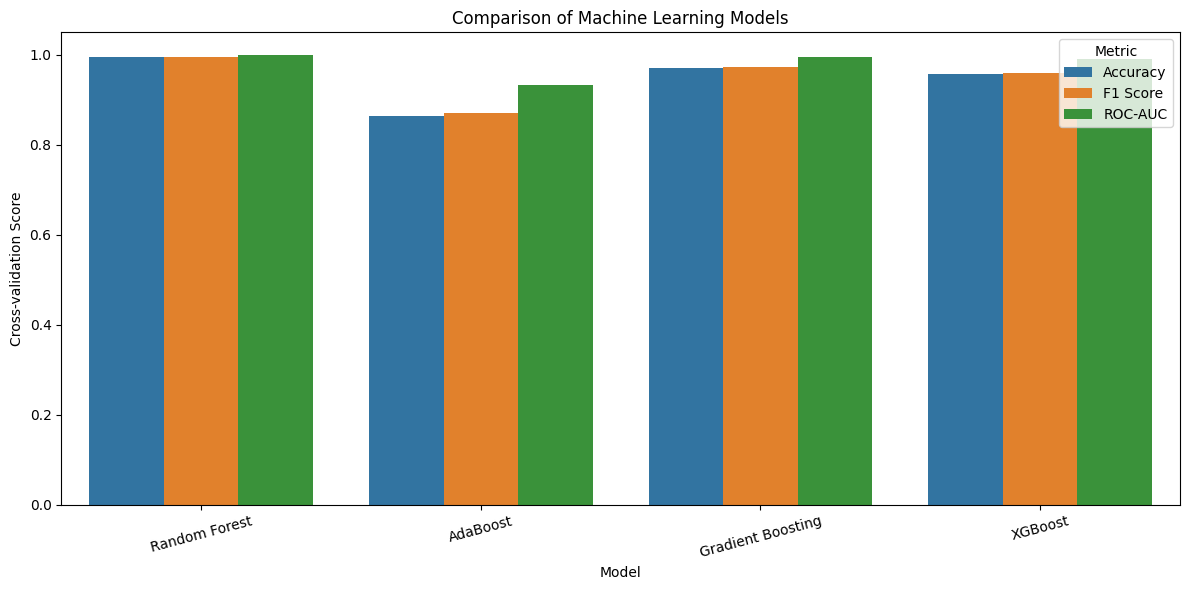

In [6]:
results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Models")
plt.ylim(0, 1.05)
plt.ylabel("Cross-validation Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

6. Feature importance visualization

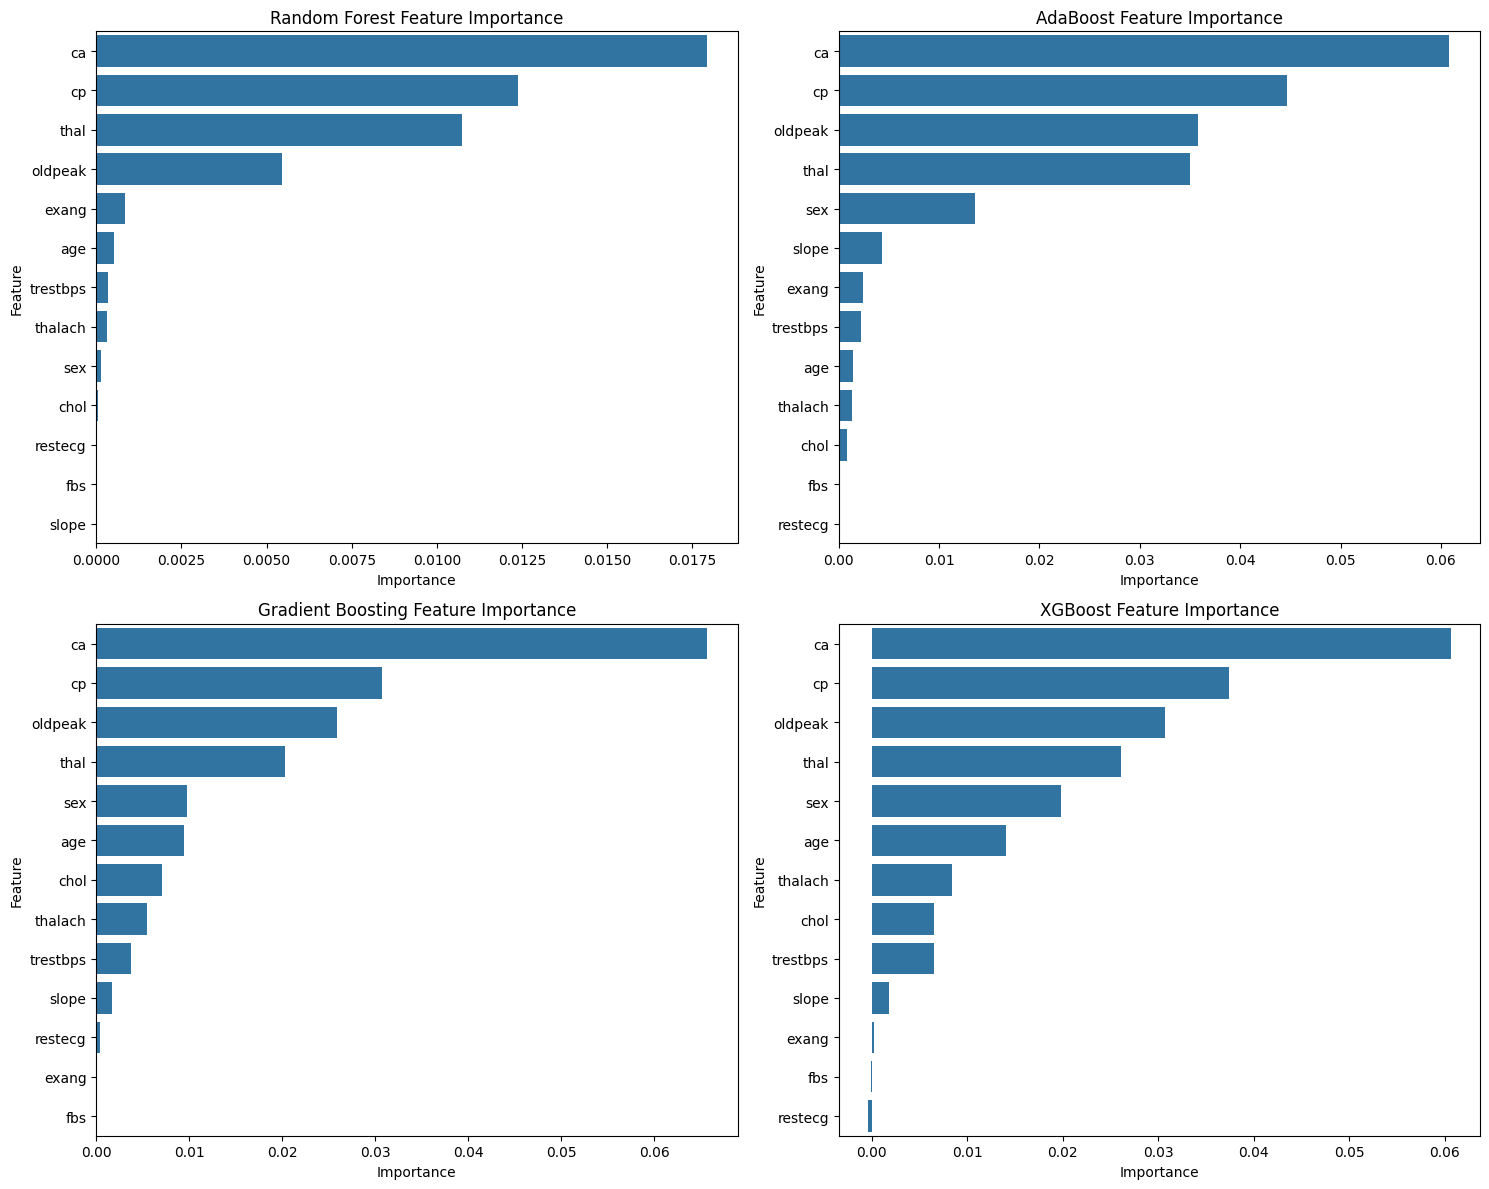

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, (name, model) in zip(axes.flat, models.items()):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    importance = permutation_importance(
        pipeline,
        X_test,
        y_test,
        n_repeats=10,
        random_state=42,
        scoring="roc_auc",
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance.importances_mean
    }).sort_values("Importance", ascending=False).head(15)

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature",
        ax=ax
    )

    ax.set_title(name + " Feature Importance")

plt.tight_layout()
plt.show()

**7. Learning rate and n_estimators: Overfitting experiment**

Here we'll experiment with three boosting algorithms:
- AdaBoost
- Gradient Boosting
- XGBoost

We'll vary:
- Learning rate: 0.01, 0.05, 0.1, 0.2
- Number of estimators: 50, 100, 200, 400
We'll compare training and validation accuracy.

In [11]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
estimators = [50, 100, 200, 400]

boosting_models = {
    "AdaBoost": AdaBoostClassifier,

    "Gradient Boosting": GradientBoostingClassifier,

    "XGBoost": XGBClassifier
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
overfit_results = []

for model_name, model_class in boosting_models.items():
    for lr in learning_rates:
        for n in estimators:
            if model_name == "XGBoost":
                model = model_class(learning_rate=lr, n_estimators=n, max_depth=3,
                                    eval_metric="logloss", random_state=42, n_jobs=1)
            else:
                model = model_class(learning_rate=lr, n_estimators=n, random_state=42)

            pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", model)])
            s = cross_validate(pipeline, X_train, y_train, cv=cv,
                               scoring="accuracy", return_train_score=True, n_jobs=-1)

            train_acc, val_acc = s["train_score"].mean(), s["test_score"].mean()
            overfit_results.append({
                "Model": model_name, "Learning Rate": lr, "Estimators": n,
                "Training Accuracy": train_acc, "Validation Accuracy": val_acc,
                "Overfitting Gap": train_acc - val_acc
            })

overfit_df = pd.DataFrame(overfit_results)

print(overfit_df.round(4).to_string(index=False))

            Model  Learning Rate  Estimators  Training Accuracy  Validation Accuracy  Overfitting Gap
         AdaBoost           0.01          50             0.7848               0.7695           0.0152
         AdaBoost           0.01         100             0.8357               0.8366          -0.0009
         AdaBoost           0.01         200             0.8442               0.8366           0.0076
         AdaBoost           0.01         400             0.8497               0.8415           0.0082
         AdaBoost           0.05          50             0.8476               0.8378           0.0098
         AdaBoost           0.05         100             0.8543               0.8463           0.0079
         AdaBoost           0.05         200             0.8671               0.8512           0.0159
         AdaBoost           0.05         400             0.8701               0.8585           0.0116
         AdaBoost           0.10          50             0.8546               0.84

8. Plot the overfitting trade-off

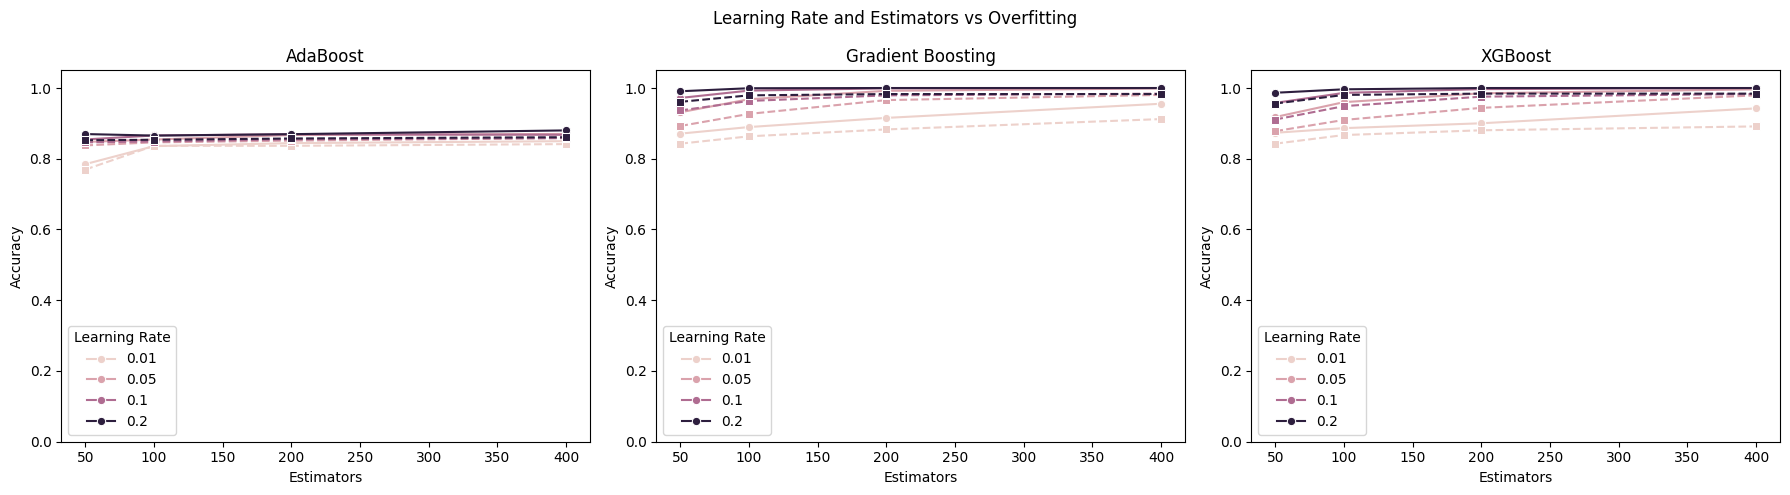

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, model_name in zip(axes, boosting_models.keys()):

    subset = overfit_df[
        overfit_df["Model"] == model_name
    ]

    sns.lineplot(
        data=subset,
        x="Estimators",
        y="Training Accuracy",
        hue="Learning Rate",
        marker="o",
        ax=ax
    )

    sns.lineplot(
        data=subset,
        x="Estimators",
        y="Validation Accuracy",
        hue="Learning Rate",
        marker="s",
        linestyle="--",
        legend=False,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Accuracy")

plt.suptitle("Learning Rate and Estimators vs Overfitting")
plt.tight_layout()
plt.show()

9. Find the best-performing configuration

In [14]:
best_config = overfit_df.sort_values(
    "Validation Accuracy",
    ascending=False
).head(10)

print("Top 10 configurations:")
print(best_config.round(4).to_string(index=False))

print("\nBest Cross-Validation Model:")
print(
    results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ).head(1).to_string(index=False)
)

Top 10 configurations:
            Model  Learning Rate  Estimators  Training Accuracy  Validation Accuracy  Overfitting Gap
          XGBoost           0.20         400             1.0000               0.9841           0.0159
          XGBoost           0.20         200             1.0000               0.9841           0.0159
Gradient Boosting           0.10         400             1.0000               0.9841           0.0159
Gradient Boosting           0.20         400             1.0000               0.9829           0.0171
          XGBoost           0.10         400             1.0000               0.9829           0.0171
Gradient Boosting           0.20         200             1.0000               0.9829           0.0171
Gradient Boosting           0.05         400             0.9988               0.9805           0.0183
          XGBoost           0.20         100             0.9963               0.9805           0.0159
Gradient Boosting           0.20         100             0.